## Robust Distribution Alignment Implementation - Feature Extractor(EfficentNetB0)

### Import torch and cuda

In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


### Imports

In [3]:
from dataclasses import dataclass
import pandas as pd
import torch
from typing import Tuple

import torchvision.transforms as T
import torchvision.transforms.functional as F

import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt

import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.metrics import roc_auc_score

import time
import matplotlib.pyplot as plt

C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


### Configuration

In [4]:
@dataclass
class Configuration:

    image_size: int = 256
    batch_size_source: int = 16
    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "efficientnet_b0"
    feature_stages: Tuple[int, ...] = (3, 5)
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("gaussian_noise", "defocus_blur", "brightness", "contrast")
    severity: int=5
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 152
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42
    assignment: str="discrete"
    aug_mode: str = "augment"

CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

### Dataset & Image transformation

In [5]:
def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image,image_size):
    return F.resize(image, [image_size,image_size], interpolation=T.InterpolationMode.BILINEAR)

def center_crop(image, image_size):
    return F.center_crop(image, [image_size,image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)
    tensor = convert_to_tensor(image)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)

### Masking ground truth

In [6]:
def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

In [7]:
class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)

In [8]:
def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))


In [9]:
class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.CFG=CFG
        self.corruption=corruption
        test_dir=os.path.join(root, category,"test")
        gt_dir=os.path.join(root, category, "ground_truth")
        self.items=[]
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p,0,None))
                else:
                    stem=os.path.splitext(os.path.basename(p))[0]
                    mp=os.path.join(gt_dir, defect, stem+"_mask.png")
                    self.items.append((p,1,mp))
        self.labels = [it[1] for it in self.items]
    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, mpath = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        x=base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m

In [10]:
def split_target(dataset, CFG):
    idx = np.arange(len(dataset))
    tr_idx, te_idx = train_test_split(
        idx, train_size=CFG.adapt_ratio, stratify=dataset.labels, random_state=CFG.seed
    )
    return Subset(dataset, tr_idx.tolist()), Subset(dataset, te_idx.tolist())

In [11]:
class AdaptDataset(Dataset):
    def __init__(self, subset, augment=True):
        self.subset = subset
        self.augment = augment

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, _, _ = self.subset[idx]
        if self.augment:
            k = random.randint(0, 3)
            x = torch.rot90(x, k, dims=(1, 2))
        return x

In [12]:
def build_loaders(root, category, corruption, CFG):
    source_ds = SourceDataset(CFG, root, category)
    target_ds = TestDataset(root, category, CFG, corruption=corruption)
    target_tr, target_te = split_target(target_ds, CFG)

    source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                               num_workers=CFG.num_workers)
    adapt_loader = DataLoader(AdaptDataset(target_tr), batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, drop_last=True)
    test_loader = DataLoader(target_te, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    return source_loader, adapt_loader, test_loader

### Feature Extraction and Memory Bank

In [13]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        self.feature_stages = tuple(CFG.feature_stages)
        self.stages = nn.ModuleList(list(net.features.children())[: max(self.feature_stages) + 1])
        for p in self.parameters():
            p.requires_grad = False

        self.eval()
        with torch.no_grad():
            out = self.forward(torch.zeros(1, 3, CFG.crop_size, CFG.crop_size))
        self.embed_dim = out.shape[-1]
        CFG.embed_dim = self.embed_dim

    def forward(self, x):
        feats = []
        for i, stage in enumerate(self.stages):
            x = stage(x)
            if i in self.feature_stages:
                feats.append(x)

        size = feats[0].shape[-2:]
        feats = [Fn.avg_pool2d(f, 3, 1, 1) for f in feats]
        feats = [f if f.shape[-2:] == size
                 else Fn.interpolate(f, size=size, mode="bilinear", align_corners=False)
                 for f in feats]
        f = torch.cat(feats, dim=1)

        B, C, H, W = f.shape
        return f.permute(0, 2, 3, 1).reshape(B, H * W, C)


@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])


@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    proj_dim = min(proj_dim, features.shape[1])
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)

    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]


def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)


model = FeatureExtractor(CFG).to(CFG.device)

source_ds = SourceDataset(CFG, CFG.root, CFG.category)
source_loader = DataLoader(source_ds, batch_size=CFG.batch_size, shuffle=False,
                           num_workers=CFG.num_workers)
memory_bank = build_memory_bank(model, source_loader, CFG)

clean_ds = TestDataset(CFG.root, CFG.category, CFG, corruption=None)
clean_loader = DataLoader(clean_ds, batch_size=CFG.batch_size, shuffle=False,
                          num_workers=CFG.num_workers)
s, y = score_images(model, clean_loader, memory_bank, CFG.device)
print("Clean image AUROC:", roc_auc_score(y, s))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Niharika.S.Reddy/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:08<00:00, 2.46MB/s]


Source patches: 163856, memory bank size N_M: 32771
Clean image AUROC: 1.0


### Base evaluation on corrupted data

In [14]:
def make_test_split(corruption, CFG):
    ds = TestDataset(CFG.root, CFG.category, CFG, corruption=corruption)
    tr, te = split_target(ds, CFG)
    return tr, te

def make_loader(subset, CFG):
    return DataLoader(subset, batch_size=CFG.batch_size, shuffle=False,num_workers=CFG.num_workers)

def evaluate(model, loader, memory_bank, CFG):
    s, y = score_images(model, loader, memory_bank, CFG.device)
    return roc_auc_score(y, s)

baseline_results = {}


_, clean_te = make_test_split(None, CFG)
baseline_results["clean"] = evaluate(model, make_loader(clean_te, CFG), memory_bank, CFG)
print(f"clean: {baseline_results['clean']:.4f}")


for c in CFG.corruptions:
    _, target_te = make_test_split(c, CFG)
    baseline_results[c] = evaluate(model, make_loader(target_te, CFG), memory_bank, CFG)
    print(f"{c}: {baseline_results[c]:.4f}")


print(pd.Series(baseline_results, name="w/o adapt AUROC").round(4))

clean: 1.0000
gaussian_noise: 0.8468
defocus_blur: 1.0000
brightness: 0.9890
contrast: 0.8578
clean             1.0000
gaussian_noise    0.8468
defocus_blur      1.0000
brightness        0.9890
contrast          0.8578
Name: w/o adapt AUROC, dtype: float64


### Sinkhorn and discretization functions

In [15]:
def cost_matrix(z, bank):
    return torch.cdist(z, bank)

def sample_patches(feats, max_patches):
    z = feats.reshape(-1, feats.shape[-1])
    if z.shape[0] > max_patches:
        idx = torch.randperm(z.shape[0], device=z.device)[:max_patches]
        z = z[idx]
    return z


@torch.no_grad()
def sinkhorn(C, eps, n_iters):
    N, M = C.shape
    Cn = C / C.mean()
    logK = -Cn / eps
    log_a = -torch.log(torch.tensor(float(N), device=C.device))
    log_b = -torch.log(torch.tensor(float(M), device=C.device))
    log_u = torch.zeros(N, device=C.device)
    log_v = torch.zeros(M, device=C.device)
    for _ in range(n_iters):
        log_u = log_a - torch.logsumexp(logK + log_v[None, :], dim=1)
        log_v = log_b - torch.logsumexp(logK + log_u[:, None], dim=0)
    return torch.exp(logK + log_u[:, None] + log_v[None, :])


@torch.no_grad()
def discretize(gamma):
    N, M = gamma.shape
    pi = torch.zeros(N, M, dtype=torch.bool, device=gamma.device)
    pi[torch.arange(N, device=gamma.device), gamma.argmax(dim=1)] = True
    pi[gamma.argmax(dim=0), torch.arange(M, device=gamma.device)] = True
    return pi


def robust_sinkhorn_loss(feats, bank, CFG, return_stats=False):
    z = sample_patches(feats, CFG.max_adapt_patches)
    C = cost_matrix(z, bank)
    gamma = sinkhorn(C.detach(), CFG.sinkhorn_eps, CFG.sinkhorn_iters)
    pi = discretize(gamma)
    loss = C[pi].sum() / z.shape[0]
    if return_stats:
        return loss, gamma, pi
    return loss


tr, _ = make_test_split("gaussian_noise", CFG)
batch = next(iter(DataLoader(AdaptDataset(tr), batch_size=CFG.batch_size, shuffle=True)))

with torch.no_grad():
    feats = model(batch.to(CFG.device))
loss, gamma, pi = robust_sinkhorn_loss(feats, memory_bank, CFG, return_stats=True)

N, M = gamma.shape
print("loss:", loss.item())
print("row sums vs 1/N_tp:", gamma.sum(1).mean().item(), 1 / N)
print("col sums vs 1/N_M :", gamma.sum(0).mean().item(), 1 / M)
print("nonzeros in pi:", pi.sum().item(), "of", N * M)

loss: 1238.842041015625
row sums vs 1/N_tp: 0.0009765629656612873 0.0009765625
col sums vs 1/N_M : 3.0514798709191382e-05 3.0514784413048123e-05
nonzeros in pi: 33238 of 33557504


### Adaptation loop, batchNorm-only updates

In [16]:
def make_adapt_model(CFG):
    m = FeatureExtractor(CFG).to(CFG.device)
    bn_params = []
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            for p in (mod.weight, mod.bias):
                p.requires_grad = True
                bn_params.append(p)
    m.eval()
    return m, bn_params


def adapt(model, bn_params, adapt_subset, memory_bank, CFG):
    loader = DataLoader(AdaptDataset(adapt_subset, augment=True), batch_size=CFG.adapt_batch_size, shuffle=True, num_workers=CFG.num_workers)
    opt = torch.optim.Adam(bn_params, lr=CFG.sinkhorn_lr)
    history = []
    for epoch in range(CFG.epochs):
        model.eval()
        total, n = 0.0, 0
        for x in loader:
            feats = model(x.to(CFG.device))
            loss = robust_sinkhorn_loss(feats, memory_bank, CFG)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        history.append(total / n)
        print(f"  epoch {epoch+1}/{CFG.epochs}  loss {history[-1]:.4f}")
    return history


def run_roda(corruption, memory_bank, CFG):
    torch.manual_seed(CFG.seed); random.seed(CFG.seed); np.random.seed(CFG.seed)
    target_tr, target_te = make_test_split(corruption, CFG)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    return auroc, history


auroc, hist = run_roda("gaussian_noise", memory_bank, CFG)
print(f"gaussian_noise  w/o adapt: {baseline_results['gaussian_noise']:.4f}  RoDA: {auroc:.4f}")

  epoch 1/10  loss 1220.9906
  epoch 2/10  loss 1227.0323
  epoch 3/10  loss 1206.9081
  epoch 4/10  loss 1207.9834
  epoch 5/10  loss 1207.7197
  epoch 6/10  loss 1192.8481
  epoch 7/10  loss 1180.6827
  epoch 8/10  loss 1179.0253
  epoch 9/10  loss 1173.7734
  epoch 10/10  loss 1163.7056
gaussian_noise  w/o adapt: 0.8468  RoDA: 0.8517


### Run RoDA on all corruptions and compare

[gaussian_noise] seed 0
  epoch 1/10  loss 1243.8351
  epoch 2/10  loss 1229.8196
  epoch 3/10  loss 1214.2016
  epoch 4/10  loss 1217.2351
  epoch 5/10  loss 1196.1940
  epoch 6/10  loss 1186.7451
  epoch 7/10  loss 1167.0514
  epoch 8/10  loss 1168.3735
  epoch 9/10  loss 1173.0792
  epoch 10/10  loss 1168.6881
  -> AUROC 0.8529
[gaussian_noise] seed 1
  epoch 1/10  loss 1230.0193
  epoch 2/10  loss 1216.9289
  epoch 3/10  loss 1204.5757
  epoch 4/10  loss 1213.5676
  epoch 5/10  loss 1206.4137
  epoch 6/10  loss 1191.4583
  epoch 7/10  loss 1184.0906
  epoch 8/10  loss 1184.8911
  epoch 9/10  loss 1173.6070
  epoch 10/10  loss 1178.6141
  -> AUROC 0.8529
[gaussian_noise] seed 2
  epoch 1/10  loss 1235.3452
  epoch 2/10  loss 1233.8203
  epoch 3/10  loss 1231.0428
  epoch 4/10  loss 1219.3607
  epoch 5/10  loss 1190.6531
  epoch 6/10  loss 1180.5378
  epoch 7/10  loss 1180.7387
  epoch 8/10  loss 1170.7130
  epoch 9/10  loss 1176.8942
  epoch 10/10  loss 1160.8334
  -> AUROC 0.8529
[

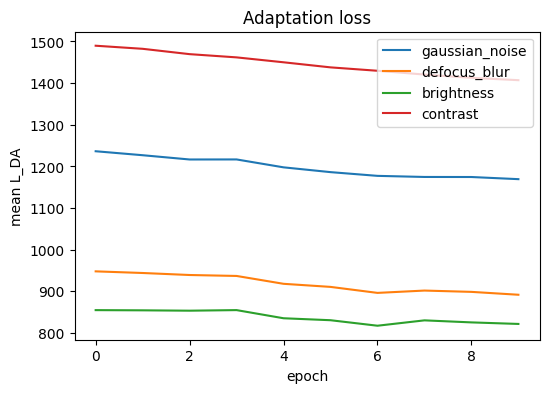

In [17]:
CFG.sinkhorn_lr = 1e-4
CFG.epochs = 10
SEEDS = [0,1,2]

class CachedDataset(Dataset):
    def __init__(self, subset):
        self.items = [subset[i] for i in range(len(subset))]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]


def run_roda_seed(target_tr, target_te, memory_bank, CFG, seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    auroc = evaluate(model_a, make_loader(target_te, CFG), memory_bank, CFG)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return auroc, history

roda_runs = {}
histories = {}


for c in CFG.corruptions:
    t0 = time.time()
    tr, te = make_test_split(c, CFG)
    tr, te = CachedDataset(tr), CachedDataset(te)
    roda_runs[c], histories[c] = [], []
    for sd in SEEDS:
        print(f"[{c}] seed {sd}")
        a, h = run_roda_seed(tr, te, memory_bank, CFG, sd)
        roda_runs[c].append(a)
        histories[c].append(h)
        print(f"  -> AUROC {a:.4f}")
    print(f"[{c}] done in {time.time()-t0:.0f}s\n")


rows = []
for c in CFG.corruptions:
    m, s = np.mean(roda_runs[c]), np.std(roda_runs[c])
    rows.append({
        "corruption": c,
        "clean": baseline_results["clean"],
        "w/o adapt": baseline_results[c],
        "RoDA mean":m,
        "RoDA std":s,
        "diff":m-baseline_results[c],
    })
results_df = pd.DataFrame(rows).set_index("corruption").round(4)
print(results_df)

plt.figure(figsize=(6,4))
for c in CFG.corruptions:
    plt.plot(np.mean(histories[c], axis=0), label=c)
plt.xlabel("epoch")
plt.ylabel("mean L_DA")
plt.legend()
plt.title("Adaptation loss")
plt.show()

### Running RoDA on all MVTec Categories

In [19]:
import gc, time
CFG.assignment, CFG.aug_mode = "discrete", "augment"

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
              "metal_nut", "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper"]
RESULTS_CSV = "roda_results_all.csv"


CFG.coreset_ratio = 0.1

def run_category(cat, base_model, CFG):
    CFG.category = cat
    src_loader = DataLoader(SourceDataset(CFG, CFG.root, cat), batch_size=CFG.batch_size,
                            shuffle=False, num_workers=CFG.num_workers)
    bank = build_memory_bank(base_model, src_loader, CFG)

    rows = []
    for c in [None] + list(CFG.corruptions):
        tr, te = make_test_split(c, CFG)
        tr, te = CachedDataset(tr), CachedDataset(te)
        before = evaluate(base_model, make_loader(te, CFG), bank, CFG)
        if c is None:
            rows.append(dict(category=cat, corruption="clean", before=before, after=np.nan, std=np.nan))
            continue
        aurocs = [run_roda_seed(tr, te, bank, CFG, sd)[0] for sd in SEEDS]
        rows.append(dict(category=cat, corruption=c, before=before,
                         after=np.mean(aurocs), std=np.std(aurocs)))
        print(f"  {cat:12s} {c:15s} before {before:.4f}  after {np.mean(aurocs):.4f}")
        del tr, te
    del bank
    gc.collect(); torch.cuda.empty_cache()
    return rows


base_model = FeatureExtractor(CFG).to(CFG.device)
done = set(pd.read_csv(RESULTS_CSV)["category"]) if os.path.exists(RESULTS_CSV) else set()

for cat in CATEGORIES:
    if cat in done:
        continue
    t0 = time.time()
    print(f"[{cat}]")
    rows = run_category(cat, base_model, CFG)
    pd.DataFrame(rows).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
    print(f"[{cat}] done in {(time.time()-t0)/60:.1f} min\n")


df = pd.read_csv(RESULTS_CSV)
corr = df[df.corruption != "clean"]
print("Per category (after adaptation):")
print(corr.pivot(index="category", columns="corruption", values="after").round(4))
summary = corr.groupby("corruption")[["before", "after"]].mean()
summary.loc["mean"] = summary.mean()
summary["clean (mean)"] = df[df.corruption == "clean"]["before"].mean()
print("\nAverage over categories:")
print((summary * 1).round(4))

CFG.category = "bottle"

[bottle]
Source patches: 163856, memory bank size N_M: 16385
  bottle       gaussian_noise  before 0.8493  after 0.8574
  bottle       defocus_blur    before 1.0000  after 1.0000
  bottle       brightness      before 0.9939  after 0.9902
  bottle       contrast        before 0.8738  after 0.9203
[bottle] done in 5.3 min

[cable]
Source patches: 175616, memory bank size N_M: 17561
  cable        gaussian_noise  before 0.8837  after 0.9178
  cable        defocus_blur    before 0.9457  after 0.9666
  cable        brightness      before 0.9195  after 0.9291
  cable        contrast        before 0.5825  after 0.7582
[cable] done in 8.1 min

[capsule]
Source patches: 171696, memory bank size N_M: 17169
  capsule      gaussian_noise  before 0.5574  after 0.6322
  capsule      defocus_blur    before 0.6294  after 0.8047
  capsule      brightness      before 0.7210  after 0.7487
  capsule      contrast        before 0.4754  after 0.6326
[capsule] done in 7.1 min

[carpet]
Source patches: 219520

## Calculating Recall Score

In [20]:
def get_threshold_at_fpr(normal_scores, target_fpr=0.05):
    normal_scores = np.asarray(normal_scores).reshape(-1)
    threshold = np.quantile(normal_scores, 1.0 - target_fpr)
    return threshold


def compute_recall(scores, labels, threshold):
    scores = np.asarray(scores).reshape(-1)
    labels = np.asarray(labels).reshape(-1)

    preds = (scores >= threshold).astype(int)
    tp = np.sum((preds == 1) & (labels == 1))
    fn = np.sum((preds == 0) & (labels == 1))

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return recall, tp, fn


def evaluate_recall(model, test_loader, memory_bank, CFG, normal_loader=None, target_fpr=0.05):
    test_scores, test_labels = score_images(
        model, test_loader, memory_bank, CFG.device
    )

    if normal_loader is not None:
        normal_scores, _ = score_images(
            model, normal_loader, memory_bank, CFG.device
        )
    else:
        normal_scores = test_scores[test_labels == 0]

    threshold = get_threshold_at_fpr(normal_scores, target_fpr)
    recall, tp, fn = compute_recall(test_scores, test_labels, threshold)

    return {
        "recall": recall,
        "threshold": threshold,
        "target_fpr": target_fpr,
        "true_positives": int(tp),
        "false_negatives": int(fn),
        "defective_images": int(tp + fn),
    }

In [21]:
def recall_before_roda(base_model, test_subset, memory_bank, CFG, target_fpr=0.05):
    return evaluate_recall(base_model, make_loader(test_subset, CFG), memory_bank, CFG,
                           normal_loader=None, target_fpr=target_fpr)

def run_roda_seed_with_recall(target_tr, target_te, memory_bank, CFG, seed, target_fpr=0.05):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    model_a, bn_params = make_adapt_model(CFG)
    history = adapt(model_a, bn_params, target_tr, memory_bank, CFG)
    res = evaluate_recall(model_a, make_loader(target_te, CFG), memory_bank, CFG,
                          normal_loader=None, target_fpr=target_fpr)
    del model_a, bn_params
    torch.cuda.empty_cache()
    return res, history

In [22]:
import io
from contextlib import redirect_stdout

CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
              "metal_nut", "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper"]
SEEDS = [0, 1, 2]
TARGET_FPR = 0.10
RECALL_CSV = "roda_recall_results.csv"
all_results = []

base_model = FeatureExtractor(CFG).to(CFG.device)

for category in CATEGORIES:
    with cfg_override(CFG, category=category, coreset_ratio=0.1):
        src = DataLoader(SourceDataset(CFG, CFG.root, category), batch_size=CFG.batch_size,
                         shuffle=False, num_workers=CFG.num_workers)
        bank = build_memory_bank(base_model, src, CFG)

        for corruption in CFG.corruptions:
            tr, te = make_test_split(corruption, CFG)
            tr, te = CachedDataset(tr), CachedDataset(te)

            before = recall_before_roda(base_model, te, bank, CFG, TARGET_FPR)
            before.update(category=category, corruption=corruption, model="before_roda")
            all_results.append(before)

            recalls = []
            for seed in SEEDS:
                with redirect_stdout(io.StringIO()):
                    res, _ = run_roda_seed_with_recall(tr, te, bank, CFG, seed, TARGET_FPR)
                recalls.append(res["recall"])
            all_results.append(dict(category=category, corruption=corruption, model="after_roda",
                                    recall=float(np.mean(recalls)), recall_std=float(np.std(recalls)),
                                    target_fpr=TARGET_FPR))
            print(f"{category:12s} | {corruption:15s} | "
                  f"before {before['recall']:.4f} | after {np.mean(recalls):.4f}")

        del bank
        torch.cuda.empty_cache()
    pd.DataFrame(all_results).to_csv(RECALL_CSV, index=False)

recall_df = pd.DataFrame(all_results)
recall_pivot = recall_df.pivot_table(index=["category", "corruption"],
                                     columns="model", values="recall").reset_index()
recall_pivot["recall_improvement"] = recall_pivot["after_roda"] - recall_pivot["before_roda"]
print(recall_pivot.round(4))
recall_pivot.to_csv("roda_recall_before_after-0.10fpr.csv", index=False)

print(CFG.category, CFG.coreset_ratio)

Source patches: 163856, memory bank size N_M: 16385
bottle       | gaussian_noise  | before 0.8039 | after 0.8039
bottle       | defocus_blur    | before 1.0000 | after 1.0000
bottle       | brightness      | before 0.9804 | after 0.9673
bottle       | contrast        | before 0.6667 | after 0.7843
Source patches: 175616, memory bank size N_M: 17561
cable        | gaussian_noise  | before 0.7432 | after 0.7883
cable        | defocus_blur    | before 0.8378 | after 0.8784
cable        | brightness      | before 0.7838 | after 0.8378
cable        | contrast        | before 0.3514 | after 0.5315
Source patches: 171696, memory bank size N_M: 17169
capsule      | gaussian_noise  | before 0.2045 | after 0.2955
capsule      | defocus_blur    | before 0.4205 | after 0.5152
capsule      | brightness      | before 0.5000 | after 0.3977
capsule      | contrast        | before 0.0227 | after 0.0833
Source patches: 219520, memory bank size N_M: 21952
carpet       | gaussian_noise  | before 0.9028 |

In [ ]:
# plots for auroc and confusion matric for before roda